<a href="https://colab.research.google.com/github/Andressuz2460/Optativa_II_TDS/blob/main/Regresion_Polinomica_Colab.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Regresión polinómica desde cero — notebook completo, explicado e interpretado

**Clase práctica · Fundamentos de Machine Learning · Google Colab y VS Code**  
**Nivel:** inicial, después de regresión lineal múltiple · **Datos:** sintéticos, incorporados en el propio archivo · **No requiere CSV, Drive ni acceso a Internet**

## Propósito de aprendizaje

En la clase previa aprendimos que una regresión lineal relaciona las variables predictoras y la variable respuesta por medio de una suma de coeficientes. Ahora aprenderemos qué ocurre cuando esa relación **no es recta**: puede aumentar rápidamente y después crecer más despacio, estabilizarse o disminuir.

Al terminar, podrás **explicar cada cálculo, cada tabla y cada gráfica**, interpretar coeficientes y unidades, comparar grados, identificar subajuste y sobreajuste, realizar predicciones, evaluar en validación/prueba y reconocer límites éticos y estadísticos.

> **Advertencia científica:** las 420 observaciones de este notebook son **simuladas**. Los resultados ilustran técnicas, pero no representan patrones verdaderos de rendimiento académico. Una relación observada no prueba causalidad.

**Ruta de la clase:** datos → exploración → ecuación y términos polinómicos → grado 1 vs. grado 2 → coeficientes y predicción manual → evaluación → selección de grado sin filtrar información → residuos → sobreajuste → polinomios con varias variables → conclusiones y preguntas.

**Cómo trabajar:** ejecuta las celdas en orden. Después de cada ejecución, lee el comentario explicativo y el análisis numérico impreso. No cambies la semilla si deseas reproducir exactamente los resultados guardados.

## 1. ¿Qué significa regresión polinómica y cómo se diferencia de regresión lineal?

La regresión lineal simple supone una **recta**: \(\hat y=\beta_0+\beta_1 x\). Si aumenta \(x\) una unidad, la predicción aumenta siempre la misma cantidad \(\beta_1\). La pendiente no cambia.

La regresión polinómica de **grado 2** supone una **curva**: \(\hat y=\beta_0+\beta_1 x+\beta_2 x^2\). Aquí el impacto de aumentar \(x\) depende del valor inicial de \(x\). Una unidad más no produce la misma diferencia en todos los puntos.

Para **grado 3** agregamos \(\beta_3 x^3\); para **grado 4**, \(\beta_4 x^4\), etc. El grado indica el **mayor exponente utilizado**, no la cantidad de registros ni el porcentaje de precisión.

**¿Por qué sigue siendo una regresión lineal en parámetros?** Porque la predicción es una suma de términos, cada uno multiplicado por un coeficiente \(\beta\). La curvatura aparece en las variables transformadas (por ejemplo, \(x^2\)), mientras los coeficientes entran linealmente. `PolynomialFeatures` construye columnas nuevas; `LinearRegression` estima sus coeficientes por mínimos cuadrados.

**Error frecuente:** un polinomio de grado 2 no es automáticamente mejor que una recta. Debemos comprobarlo con datos no usados para ajustar los coeficientes.

**Ejemplo hipotético:** estudiar más horas puede asociarse inicialmente con mejores notas, pero la diferencia marginal puede disminuir a medida que aumentan las horas. En la realidad esa relación necesita evidencia; en este notebook la programaremos deliberadamente para aprender.

## 2. Preparar Python: bibliotecas, semilla y significado de cada herramienta

- `numpy`: números, potencias, generador aleatorio y cálculos.
- `pandas`: tablas (`DataFrame`), conteos y estadísticas.
- `matplotlib`: gráficas.
- `PolynomialFeatures`: genera las columnas \(x,x^2,\ldots\).
- `StandardScaler`: transforma escalas para mejorar la estabilidad numérica en polinomios de grados elevados.
- `Pipeline`: encadena transformaciones y modelo **sin ajustar transformadores con datos de validación o prueba**.
- `train_test_split`, `KFold`, `cross_val_score`: separación y validación.
- `LinearRegression`, `DummyRegressor`: modelo principal y referencia sencilla.
- `MAE`, `MSE`, `RMSE`, `R²`: mediciones de error y ajuste.

La semilla fija la reproducibilidad, **no** garantiza representatividad de los datos.

In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LinearRegression
from sklearn.dummy import DummyRegressor
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

SEMILLA = 2026
rng = np.random.default_rng(SEMILLA)
pd.set_option("display.max_columns", 20)
print("Bibliotecas importadas. Semilla:", SEMILLA)

Bibliotecas importadas. Semilla: 2026


## 3. Crear una base de datos **dentro del notebook**: 420 estudiantes ficticios

Se generarán estas variables:

| Columna | Unidad / codificación | Función en el ejercicio |
|---|---|---|
| `horas_estudio_semana` | Horas de 0 a 20 | Predictor principal de la relación curva |
| `promedio_anterior` | Nota de 2,0 a 5,0 | Predictor adicional del modelo múltiple |
| `asistencia_pct` | Porcentaje, 50 a 100 | Predictor adicional del modelo múltiple |
| `trabaja` | 0 no / 1 sí | Predictor binario del modelo múltiple |
| `nota_final` | Nota entre 0 y 5 | Variable objetivo que se predice |

### ¿De dónde salen las notas simuladas?

Programamos una fórmula didáctica que contiene una relación curva con las horas:

\[
y^* = 0,10 + 0,30h - 0,009h^2 + 0,40p + 0,007a - 0,12t + \varepsilon
\]

Donde \(h\) son las horas, \(p\) el promedio previo, \(a\) la asistencia medida de 0 a 100, \(t\) vale 0 o 1 y \(\varepsilon\) es ruido aleatorio de media teórica cero y desviación estándar 0,20. Finalmente se limita la nota al rango de 0 a 5 y se redondea a dos decimales.

**Interpretación:** el coeficiente real de \(h^2\) en la simulación es negativo (−0,009), lo cual produce **rendimientos marginales decrecientes**: el aumento asociado con una hora adicional tiende a reducirse conforme crece \(h\). Los demás coeficientes incorporan variaciones que una regresión que use solo horas no podrá capturar.

> Esta fórmula es una **decisión de simulación**, no una conclusión sobre estudiantes reales. El término \(\varepsilon\) evita que todas las observaciones caigan exactamente sobre una misma curva.

In [ ]:
n_estudiantes = 420
horas = rng.uniform(0, 20, n_estudiantes)
promedio = np.clip(rng.normal(3.5, 0.52, n_estudiantes), 2.0, 5.0)
asistencia = np.clip(rng.normal(81, 10, n_estudiantes), 50, 100)
trabaja = rng.binomial(1, 0.38, n_estudiantes)
ruido = rng.normal(0, 0.20, n_estudiantes)
nota_sin_limitar = (0.10 + 0.30*horas - 0.009*horas**2
                    + 0.40*promedio + 0.007*asistencia - 0.12*trabaja + ruido)
nota_final = np.round(np.clip(nota_sin_limitar, 0, 5), 2)
datos = pd.DataFrame({
    "horas_estudio_semana": np.round(horas, 2),
    "promedio_anterior": np.round(promedio, 2),
    "asistencia_pct": np.round(asistencia, 2),
    "trabaja": trabaja,
    "nota_final": nota_final
})
print("Tamaño de la base (filas, columnas):", datos.shape)
display(datos.head(8))
print("Notas en los límites 0 o 5:", int(((datos.nota_final==0)|(datos.nota_final==5)).sum()))

Tamaño de la base (filas, columnas): (420, 5)


,horas_estudio_semana,promedio_anterior,asistencia_pct,trabaja,nota_final
0,3.58,3.56,90.42,1,2.84
1,12.80,3.83,79.97,1,4.36
2,9.35,4.36,79.57,0,4.37
3,7.41,3.69,80.37,1,3.62
4,7.10,3.75,71.50,0,3.67
5,15.81,4.38,70.57,1,4.47
6,18.10,3.10,62.01,0,4.23
7,3.55,3.00,81.23,1,2.99


Notas en los límites 0 o 5: 6


### Cómo interpretar la primera tabla, columna por columna

1. **Cada fila** representa una observación ficticia; **cada columna** una variable. `shape=(420,5)` significa 420 registros y cinco campos, no que haya 420 predictores.
2. Las primeras ocho filas de `head(8)` son un **vistazo**, no una muestra estadística que represente necesariamente al conjunto.
3. Un valor `trabaja=1` es una **categoría codificada**, no «una hora de trabajo».
4. `nota_final` es la variable a estimar (\(y\)). El modelo desconocerá sus valores para los estudiantes de prueba al estimar los coeficientes.
5. Un dato redondeado a dos decimales implica pérdida leve de precisión; en esta simulación la aceptamos por claridad.
6. Si el conteo de notas exactamente en 0 o 5 es distinto de cero, existe **censura por límites**; la regresión lineal ordinaria no impone dichos límites cuando predice.

**Pregunta para clase:** ¿por qué no podemos decir que el ruido simulado constituye un error del algoritmo? Porque está presente en los datos **antes** de entrenar; el error de predicción se calcula **después**, comparando la estimación con la respuesta observada.

## 4. Verificar tipos, faltantes, duplicados y valores imposibles

`info()` informa tipos y observaciones no nulas. `isna().sum()` cuenta faltantes. `duplicated()` detecta filas idénticas (no necesariamente estudiantes duplicados). Verificaremos también que horas estén entre 0 y 20, que asistencia esté entre 0 y 100, que notas estén entre 0 y 5 y que `trabaja` sea 0 o 1.

**Importante:** no encontrar valores nulos no prueba que los datos sean correctos o representativos.

In [ ]:
print("ESTRUCTURA:")
datos.info()
print("\nVALORES NULOS POR COLUMNA:\n", datos.isna().sum().to_string())
print("\nFILAS TOTALMENTE DUPLICADAS:", datos.duplicated().sum())
print("VALORES FUERA DE RANGO:")
print("Horas:", int((~datos.horas_estudio_semana.between(0,20)).sum()))
print("Asistencia:", int((~datos.asistencia_pct.between(0,100)).sum()))
print("Nota final:", int((~datos.nota_final.between(0,5)).sum()))
print("Trabaja (fuera de 0/1):", int((~datos.trabaja.isin([0,1])).sum()))

ESTRUCTURA:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 420 entries, 0 to 419
Data columns (total 5 columns):
 #   Column                Non-Null Count  Dtype  
---  ------                --------------  -----  
 0   horas_estudio_semana  420 non-null    float64
 1   promedio_anterior     420 non-null    float64
 2   asistencia_pct        420 non-null    float64
 3   trabaja               420 non-null    int64  
 4   nota_final            420 non-null    float64
dtypes: float64(4), int64(1)
memory usage: 16.5 KB

VALORES NULOS POR COLUMNA:
 horas_estudio_semana    0
promedio_anterior       0
asistencia_pct          0
trabaja                 0
nota_final              0

FILAS TOTALMENTE DUPLICADAS: 0
VALORES FUERA DE RANGO:
Horas: 0
Asistencia: 0
Nota final: 0
Trabaja (fuera de 0/1): 0


## 5. Estadística descriptiva: explicar todos los números de `describe()`

**Lectura de las filas:**

- `count` = cantidad de valores válidos de cada variable.
- `mean` = media aritmética: suma de valores / cantidad de registros.
- `std` = desviación estándar muestral: grado de dispersión, **en la unidad original**.
- `min` / `max` = mínimo y máximo observados.
- `25%`, `50%`, `75%` = primer cuartil, mediana y tercer cuartil. El intervalo del 25 % al 75 % contiene aproximadamente la mitad central de los datos.

**Para `trabaja`:** su media representa la proporción codificada con 1; sus cuartiles no son «horas trabajadas». No interpretes correlaciones como causalidad.

Después de imprimir la tabla, una segunda celda elaborará interpretaciones **usando los valores realmente calculados**, no cifras inventadas.

In [ ]:
resumen = datos.describe()
display(resumen.round(3))
print("Mediana nota:", round(datos.nota_final.median(), 3))
print("RIC nota:", round(datos.nota_final.quantile(.75)-datos.nota_final.quantile(.25), 3))

,horas_estudio_semana,promedio_anterior,asistencia_pct,trabaja,nota_final
count,420.000,420.000,420.000,420.000,420.000
mean,10.100,3.513,80.477,0.407,3.835
std,5.596,0.525,9.571,0.492,0.765
min,0.040,2.000,53.980,0.000,1.560
25%,5.637,3.150,73.918,0.000,3.330
50%,10.220,3.530,80.570,0.000,4.040
75%,14.805,3.870,87.232,1.000,4.402
max,19.990,5.000,100.000,1.000,5.000


Mediana nota: 4.04
RIC nota: 1.072


In [ ]:
print("LECTURA NUMÉRICA AUTOMÁTICA:")
print(f"• Se observaron {len(datos)} estudiantes ficticios y {datos.shape[1]} variables.")
print(f"• Horas: promedio {datos.horas_estudio_semana.mean():.2f} h/semana; desviación {datos.horas_estudio_semana.std():.2f} h;")
print(f"  mínimo {datos.horas_estudio_semana.min():.2f}, mediana {datos.horas_estudio_semana.median():.2f}, máximo {datos.horas_estudio_semana.max():.2f}.")
print(f"• Nota final: media {datos.nota_final.mean():.2f}; mediana {datos.nota_final.median():.2f}; desviación {datos.nota_final.std():.2f}.")
print(f"• Cuartiles de nota: Q1={datos.nota_final.quantile(.25):.2f}; Q3={datos.nota_final.quantile(.75):.2f}.")
print(f"• Trabaja=1 en {datos.trabaja.mean()*100:.1f}% de las observaciones.")
print("Un menor valor de desviación no es siempre mejor: solo describe menor dispersión.")

LECTURA NUMÉRICA AUTOMÁTICA:
• Se observaron 420 estudiantes ficticios y 5 variables.
• Horas: promedio 10.10 h/semana; desviación 5.60 h;
  mínimo 0.04, mediana 10.22, máximo 19.99.
• Nota final: media 3.84; mediana 4.04; desviación 0.77.
• Cuartiles de nota: Q1=3.33; Q3=4.40.
• Trabaja=1 en 40.7% de las observaciones.
Un menor valor de desviación no es siempre mejor: solo describe menor dispersión.


## 6. Primera gráfica: ¿las horas y la nota parecen formar una recta?

**Eje horizontal:** horas semanales. **Eje vertical:** nota final sobre 5. **Cada punto:** un estudiante ficticio.

El patrón esperado es una asociación positiva que puede **aplanarse** conforme aumentan las horas. Como las otras tres características y el ruido también intervienen, distintos estudiantes con las mismas horas pueden tener distintas notas.

**Qué buscar:**

- Si los puntos se orientan en una recta, el grado 1 podría ser suficiente.
- Si parecen una curva, el grado 2 puede capturarla mejor.
- Si hay dispersión, recuerda que no toda variación se explica con horas.

**Advertencia:** esta gráfica no revela por sí sola qué grado será mejor en datos nuevos; para eso utilizaremos validación.

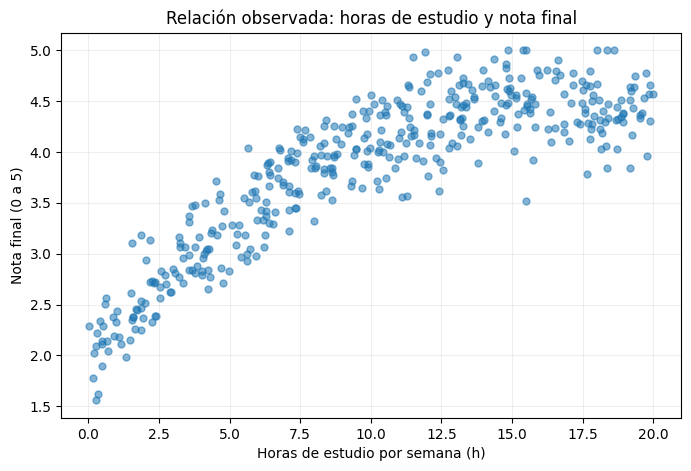

Correlación lineal de Pearson (horas, nota): 0.856


In [ ]:
plt.figure(figsize=(8,5))
plt.scatter(datos.horas_estudio_semana,datos.nota_final,alpha=.55,s=25)
plt.xlabel("Horas de estudio por semana (h)")
plt.ylabel("Nota final (0 a 5)")
plt.title("Relación observada: horas de estudio y nota final")
plt.grid(alpha=.2)
plt.show()
print("Correlación lineal de Pearson (horas, nota):",
      round(datos[['horas_estudio_semana','nota_final']].corr().iloc[0,1],4))

### ¿La correlación de Pearson identifica automáticamente una curva?

No. Pearson resume la asociación **lineal**, no toda posible relación no lineal. Una correlación positiva no significa necesariamente que una recta sea la mejor forma funcional; una curva puede tener también una correlación positiva. Tampoco implica causalidad.

## 7. ¿De dónde sale \(x^2\)? Calcular potencias manualmente

Si una persona estudia \(h=4\) horas, entonces \(h^2=4\times4=16\). Si estudia 10 horas, \(h^2=100\). La columna cuadrática no aporta otro individuo: es una **transformación de la misma medida**.

¿Por qué sirve? Porque una ecuación que multiplica un coeficiente por \(h^2\) puede tener **pendiente variable**. A diferencia de una recta, la curva cambia su inclinación.

A continuación construiremos una pequeña tabla con \(h\), \(h^2\) y \(h^3\) para entender la mecánica. Son ejemplos algebraicos, no calificaciones reales.

In [ ]:
ejemplos_horas = np.array([0,2,4,8,10,15,20],dtype=float)
tabla_potencias = pd.DataFrame({
    "h": ejemplos_horas,
    "h²": ejemplos_horas**2,
    "h³": ejemplos_horas**3
})
display(tabla_potencias)
print("Ejemplo: para 4 horas, h² =",4**2,"y h³ =",4**3)

,h,h²,h³
0,0.0,0.0,0.0
1,2.0,4.0,8.0
2,4.0,16.0,64.0
3,8.0,64.0,512.0
4,10.0,100.0,1000.0
5,15.0,225.0,3375.0
6,20.0,400.0,8000.0


Ejemplo: para 4 horas, h² = 16 y h³ = 64


## 8. `PolynomialFeatures`: cómo pasar de una columna a muchas

`PolynomialFeatures(degree=2, include_bias=False)` crea dos predictores a partir de uno: `h` y `h²`.

Por ejemplo, las filas \([2], [4], [8]\) se convierten en \([2,4], [4,16], [8,64]\). `include_bias=False` evita que el transformador agregue otra columna constante, ya que `LinearRegression` estima su propio intercepto.

**Atención:** la función no calcula automáticamente coeficientes ni notas. Solamente genera columnas; después `LinearRegression.fit()` calcula el intercepto y los coeficientes.

Con varios predictores, el transformador también crea **interacciones**, como `horas × asistencia`, además de términos cuadrados. Lo veremos al final.

In [ ]:
X_ejemplo = pd.DataFrame({"horas_estudio_semana": [2.,4.,8.]})
transformador_ejemplo = PolynomialFeatures(degree=2,include_bias=False)
matriz = transformador_ejemplo.fit_transform(X_ejemplo)
nombres = transformador_ejemplo.get_feature_names_out(X_ejemplo.columns)
display(pd.DataFrame(matriz,columns=nombres))
print("Forma antes:",X_ejemplo.shape,"/ después:",matriz.shape)
print("Transformación grado 3 del mismo ejemplo:")
poly3 = PolynomialFeatures(degree=3, include_bias=False)
display(pd.DataFrame(poly3.fit_transform(X_ejemplo),columns=poly3.get_feature_names_out()))

,horas_estudio_semana,horas_estudio_semana^2
0,2.0,4.0
1,4.0,16.0
2,8.0,64.0


Forma antes: (3, 1) / después: (3, 2)
Transformación grado 3 del mismo ejemplo:


,horas_estudio_semana,horas_estudio_semana^2,horas_estudio_semana^3
0,2.0,4.0,8.0
1,4.0,16.0,64.0
2,8.0,64.0,512.0


## 9. Separación rigurosa en entrenamiento, validación y prueba

La clase anterior utilizó entrenamiento/prueba (80/20). Aquí añadimos **validación** porque queremos escoger el mejor grado del polinomio sin utilizar anticipadamente los datos de prueba.

Utilizaremos aproximadamente **60 % entrenamiento**, **20 % validación** y **20 % prueba**:

1. **Entrenamiento:** estima los coeficientes.
2. **Validación:** compara grados 1, 2, 3, 5, 7 y 10; selecciona el grado.
3. **Prueba:** se utiliza **solo después** de escoger el modelo para obtener una estimación final de desempeño.

La semilla `random_state=42` genera siempre la misma distribución de filas; no mejora el algoritmo por sí sola.

**Cuidado con la fuga de datos:** el transformador de un `Pipeline` se ajusta únicamente sobre entrenamiento cuando llamamos `fit()`. Nunca calcularemos una normalización usando todas las notas o todo el conjunto antes de separar los datos.

**Modelo inicial:** usaremos únicamente `horas_estudio_semana`. Las otras variables seguirán en el DataFrame y se incorporarán en una sección avanzada para distinguir polinomio simple de polinomio con múltiples variables.

In [ ]:
X = datos[["horas_estudio_semana"]]
y = datos["nota_final"]
X_pre, X_prueba, y_pre, y_prueba = train_test_split(
    X,y,test_size=.20,random_state=42)
X_entrena, X_valida, y_entrena, y_valida = train_test_split(
    X_pre,y_pre,test_size=.25,random_state=42)
print("Entrenamiento:",len(X_entrena),"observaciones (",f"{len(X_entrena)/len(X):.0%}",")")
print("Validación:",len(X_valida),"observaciones (",f"{len(X_valida)/len(X):.0%}",")")
print("Prueba:",len(X_prueba),"observaciones (",f"{len(X_prueba)/len(X):.0%}",")")
print("Forma de X_entrena:",X_entrena.shape,"de y_entrena:",y_entrena.shape)

Entrenamiento: 252 observaciones ( 60% )
Validación: 84 observaciones ( 20% )
Prueba: 84 observaciones ( 20% )
Forma de X_entrena: (252, 1) de y_entrena: (252,)


## 10. Entrenar grado 1 y grado 2: la comparación principal

El **modelo de grado 1** aprende \(\hat y=b_0+b_1h\), una recta. El de **grado 2** aprende \(\hat y=b_0+b_1h+b_2h^2\), una parábola.

Para que sus coeficientes sean fáciles de interpretar, en esta primera comparación **no escalamos las horas**. Empleamos un `Pipeline` que transforma `h` en `h` y `h²` en el segundo modelo.

`fit(X_entrena, y_entrena)` estima parámetros minimizando la suma de los **residuos de entrenamiento elevados al cuadrado**. La respuesta de los estudiantes de validación/prueba permanece fuera del ajuste.

**No confundir:** una mayor flexibilidad (grado 2) puede mejorar el ajuste de entrenamiento, pero solo la validación nos dirá si mejora las predicciones no utilizadas en el ajuste.

In [ ]:
modelo_grado1 = Pipeline([
    ("potencias",PolynomialFeatures(degree=1,include_bias=False)),
    ("regresion",LinearRegression())
])
modelo_grado2 = Pipeline([
    ("potencias",PolynomialFeatures(degree=2,include_bias=False)),
    ("regresion",LinearRegression())
])
modelo_grado1.fit(X_entrena,y_entrena)
modelo_grado2.fit(X_entrena,y_entrena)
for titulo,modelo in [("Grado 1",modelo_grado1),("Grado 2",modelo_grado2)]:
    r=modelo.named_steps['regresion']
    print(f"{titulo}: intercepto={r.intercept_:.6f}, coeficientes={np.round(r.coef_,6)}")

Grado 1: intercepto=2.673609, coeficientes=[0.118087]
Grado 2: intercepto=1.951167, coeficientes=[ 0.316443 -0.009789]


## 11. Leer cada coeficiente del grado 2 y construir la ecuación con valores reales

La salida anterior muestra:

- **Intercepto \(b_0\):** predicción del modelo cuando `horas = 0`. No es necesariamente la nota real de una persona concreta porque ignoramos otras variables y existe ruido.
- **Coeficiente lineal \(b_1\) (puntos de nota/hora):** contribuye \(b_1h\) a la predicción.
- **Coeficiente cuadrático \(b_2\) (puntos de nota/hora²):** contribuye \(b_2h^2\). Si es negativo, reduce progresivamente la pendiente a medida que aumentan las horas.

**Muy importante:** \(b_1\) **no** equivale a «la nota aumenta siempre \(b_1\) por cada hora». En un polinomio, la diferencia exacta entre \(h\) y \(h+1\) es

\[
\hat y(h+1)-\hat y(h)=b_1+b_2(2h+1).
\]

La **pendiente instantánea** de la parábola es \(b_1+2b_2h\). Si \(b_2<0\), la pendiente cae cuando aumentan las horas. El vértice matemático está en \(h^*=-b_1/(2b_2)\) cuando \(b_2\ne0\). Que exista un vértice no significa que sea una recomendación pedagógica óptima.

**Diferencia con la simulación original:** los coeficientes ajustados de este modelo simple no tienen por qué coincidir con los coeficientes que generaron las notas, pues omitimos promedio anterior, asistencia y trabajo.

In [ ]:
b0 = float(modelo_grado2.named_steps['regresion'].intercept_)
b1,b2 = modelo_grado2.named_steps['regresion'].coef_.astype(float)
print(f"ECUACIÓN AJUSTADA: nota_pred = {b0:.6f} + ({b1:.6f})·h + ({b2:.6f})·h²")
print(f"Intercepto b0={b0:.4f}: nota estimada para 0 h, si usamos SOLO horas.")
print(f"b1={b1:.4f}: término lineal en puntos de nota por hora.")
print(f"b2={b2:.6f}: término cuadrático en puntos de nota por hora².")
for h in [2.,8.,14.,18.]:
    print(f"Alrededor de h={h:>4.0f}, pendiente instantánea b1+2*b2*h = {b1+2*b2*h:+.4f} puntos/h.")
    print(f"  Cambio EXACTO de h={h:.0f} a {h+1:.0f}: {b1+b2*(2*h+1):+.4f} puntos.")
if abs(b2)>1e-10:
    vertice = -b1/(2*b2)
    print(f"Vértice matemático: h*={vertice:.3f} horas; dentro del intervalo 0–20: {0<=vertice<=20}")
else:
    print("No hay vértice cuadrático definido si b2 es cercano a cero.")

ECUACIÓN AJUSTADA: nota_pred = 1.951167 + (0.316443)·h + (-0.009789)·h²
Intercepto b0=1.9512: nota estimada para 0 h, si usamos SOLO horas.
b1=0.3164: término lineal en puntos de nota por hora.
b2=-0.009789: término cuadrático en puntos de nota por hora².
Alrededor de h=   2, pendiente instantánea b1+2*b2*h = +0.2773 puntos/h.
  Cambio EXACTO de h=2 a 3: +0.2675 puntos.
Alrededor de h=   8, pendiente instantánea b1+2*b2*h = +0.1598 puntos/h.
  Cambio EXACTO de h=8 a 9: +0.1500 puntos.
Alrededor de h=  14, pendiente instantánea b1+2*b2*h = +0.0424 puntos/h.
  Cambio EXACTO de h=14 a 15: +0.0326 puntos.
Alrededor de h=  18, pendiente instantánea b1+2*b2*h = -0.0360 puntos/h.
  Cambio EXACTO de h=18 a 19: -0.0457 puntos.
Vértice matemático: h*=16.163 horas; dentro del intervalo 0–20: True


## 12. Predicción a mano: descomponer cada sumando y comprobar con `predict()`

Vamos a predecir la nota asociada con 4, 10 y 16 horas. Para cada caso se calculará:

1. El intercepto \(b_0\).
2. La contribución lineal \(b_1h\).
3. La contribución cuadrática \(b_2h^2\).
4. La suma de las tres cantidades.
5. El resultado automático de `.predict()`.

Si coinciden, verificamos que comprendimos **cómo se construye la predicción**. No estamos verificando si la predicción coincide con la nota real de un estudiante.

In [ ]:
nuevas_horas = pd.DataFrame({"horas_estudio_semana":[4.0,10.0,16.0]})
resultado_manual = pd.DataFrame({
    "horas": nuevas_horas["horas_estudio_semana"],
    "intercepto":b0,
    "aporte_lineal":b1*nuevas_horas["horas_estudio_semana"],
    "aporte_cuadratico":b2*nuevas_horas["horas_estudio_semana"]**2
})
resultado_manual["suma_manual"] = (resultado_manual["intercepto"]+
    resultado_manual["aporte_lineal"]+resultado_manual["aporte_cuadratico"])
resultado_manual["predict_sklearn"] = modelo_grado2.predict(nuevas_horas)
resultado_manual["diferencia_numerica"] = resultado_manual["suma_manual"]-resultado_manual["predict_sklearn"]
display(resultado_manual.round(6))
print("Interpretación: las diferencias finales deben ser cercanas a 0 (errores de redondeo).")

,horas,intercepto,aporte_lineal,aporte_cuadratico,suma_manual,predict_sklearn,diferencia_numerica
0,4.0,1.951167,1.265771,-0.156623,3.060315,3.060315,0.0
1,10.0,1.951167,3.164427,-0.978896,4.136698,4.136698,0.0
2,16.0,1.951167,5.063084,-2.505974,4.508276,4.508276,-0.0


Interpretación: las diferencias finales deben ser cercanas a 0 (errores de redondeo).


## 13. Gráfica de las curvas grado 1 y grado 2 sobre los datos de entrenamiento

- Los puntos son observaciones de **entrenamiento**.
- La curva de **grado 1** es recta por construcción.
- La curva de **grado 2** permite variar la pendiente.
- Una línea más próxima a los puntos en entrenamiento no garantiza mejor capacidad predictiva; usaremos validación.

La comparación visual ayuda a identificar qué estructura permite representar la curvatura. Fíjate en las zonas de pocas horas y muchas horas, donde las diferencias entre modelos pueden ser más visibles.

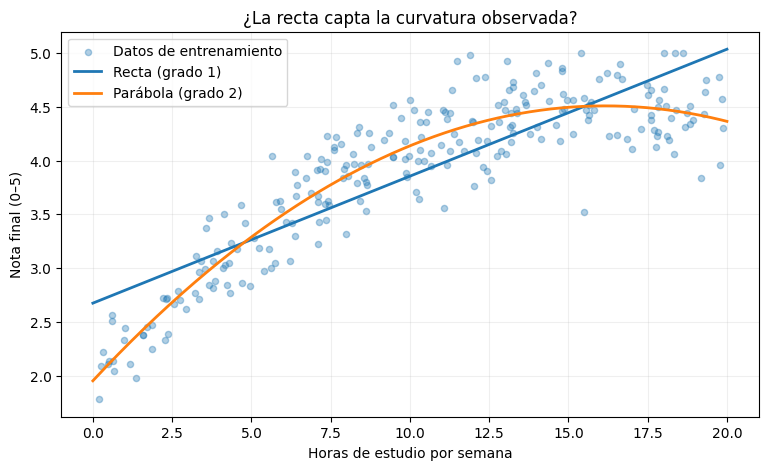

In [ ]:
malla = pd.DataFrame({"horas_estudio_semana":np.linspace(0,20,300)})
plt.figure(figsize=(9,5))
plt.scatter(X_entrena.horas_estudio_semana,y_entrena,alpha=.35,s=20,label="Datos de entrenamiento")
plt.plot(malla.horas_estudio_semana,modelo_grado1.predict(malla),lw=2,label="Recta (grado 1)")
plt.plot(malla.horas_estudio_semana,modelo_grado2.predict(malla),lw=2,label="Parábola (grado 2)")
plt.xlabel("Horas de estudio por semana")
plt.ylabel("Nota final (0–5)")
plt.title("¿La recta capta la curvatura observada?")
plt.legend();plt.grid(alpha=.2);plt.show()

## 14. Medir errores: cómo salen MAE, MSE, RMSE y R²

Para un estudiante con nota real \(y\) y nota predicha \(\hat y\):

- **Residual:** \(e=y-\hat y\). Si es positivo, el modelo **subestimó**; si es negativo, **sobreestimó**.
- **Error absoluto:** \(|e|\). Elimina el signo y mide cuánto se alejó, en puntos de nota.
- **Error cuadrático:** \(e^2\). Penaliza más las diferencias grandes, en puntos².
- **MAE:** \(\frac{1}{n}\sum|e_i|\); promedio de errores absolutos, en puntos de nota.
- **MSE:** \(\frac{1}{n}\sum e_i^2\); promedio de cuadrados, en puntos².
- **RMSE:** \(\sqrt{MSE}\); raíz del error cuadrático medio, vuelve a puntos de nota.
- **R²:** \(1-\frac{\sum e_i^2}{\sum(y_i-\bar y)^2}\). Compara la suma de errores cuadráticos con la referencia que predice la **media del conjunto evaluado**. No equivale a un porcentaje de aciertos ni prueba causalidad.

En los próximos cálculos usaremos **validación** para comparar grado 1 y 2, sin mirar aún la prueba final.

In [ ]:
def metricas(y_real,y_pred):
    return {"MAE":mean_absolute_error(y_real,y_pred),
            "MSE":mean_squared_error(y_real,y_pred),
            "RMSE":np.sqrt(mean_squared_error(y_real,y_pred)),
            "R2":r2_score(y_real,y_pred)}
filas=[]
for nombre,modelo in [("Recta grado 1",modelo_grado1),("Parábola grado 2",modelo_grado2)]:
    for conjunto,xdatos,ydatos in [("Entrenamiento",X_entrena,y_entrena),
                                   ("Validación",X_valida,y_valida)]:
        filas.append({"Modelo":nombre,"Conjunto":conjunto,**metricas(ydatos,modelo.predict(xdatos))})
comparacion_inicial=pd.DataFrame(filas)
display(comparacion_inicial.round(4))
for nombre in comparacion_inicial.Modelo.unique():
    fila=comparacion_inicial[(comparacion_inicial.Modelo==nombre)&(comparacion_inicial.Conjunto=='Validación')].iloc[0]
    print(f"{nombre}: en validación, error absoluto medio={fila.MAE:.3f} puntos; RMSE={fila.RMSE:.3f}; R²={fila.R2:.3f}.")

,Modelo,Conjunto,MAE,MSE,RMSE,R2
0,Recta grado 1,Entrenamiento,0.3187,0.1498,0.3870,0.7286
1,Recta grado 1,Validación,0.3600,0.1921,0.4383,0.7143
2,Parábola grado 2,Entrenamiento,0.2146,0.0724,0.2692,0.8687
3,Parábola grado 2,Validación,0.2399,0.0863,0.2938,0.8716


Recta grado 1: en validación, error absoluto medio=0.360 puntos; RMSE=0.438; R²=0.714.
Parábola grado 2: en validación, error absoluto medio=0.240 puntos; RMSE=0.294; R²=0.872.


### ¿Por qué MAE no es una tasa de aciertos?

Supón que el MAE fuera 0,18: eso diría que la **distancia absoluta media** entre predicción y nota real es de 0,18 puntos. No significa «82 % de aciertos» y tampoco garantiza que cada caso se haya equivocado solo 0,18 puntos. En regresión no existe naturalmente la misma noción de «acierto exacto» que en clasificación.

**Cómo juzgar bien/mal:** MAE y RMSE necesitan unidades, objetivo y **comparación**. Si un modelo básico tiene MAE=0,35 y el polinómico MAE=0,18, el segundo mejora la referencia. Un R² positivo indica mejora frente al predictor constante que utiliza la media **de ese conjunto**; si es negativo, el modelo puede funcionar peor que esa referencia.

### Comprobar una métrica «a mano» con cinco observaciones

Mostraremos cinco filas de validación, sus residuales, errores absolutos y cuadrados. Después calcularemos el promedio solo sobre esos cinco casos para practicar. **Es distinto** del MAE completo de validación, que usa todos los registros.

In [ ]:
real5 = y_valida.iloc[:5].to_numpy()
prev5 = modelo_grado2.predict(X_valida.iloc[:5])
calculo5=pd.DataFrame({"real":real5,"predicho":prev5})
calculo5["residual_real_menos_predicho"] = calculo5.real-calculo5.predicho
calculo5["error_absoluto"] = abs(calculo5.residual_real_menos_predicho)
calculo5["error_cuadrado"] = calculo5.residual_real_menos_predicho**2
display(calculo5.round(5))
print("MAE (solo estos 5) = promedio columna error_absoluto =",round(calculo5.error_absoluto.mean(),5))
print("MSE (solo estos 5) = promedio columna error_cuadrado =",round(calculo5.error_cuadrado.mean(),5))
print("RMSE (solo estos 5) = raíz MSE =",round(np.sqrt(calculo5.error_cuadrado.mean()),5))

,real,predicho,residual_real_menos_predicho,error_absoluto,error_cuadrado
0,2.85,2.80982,0.04018,0.04018,0.00161
1,3.37,3.55237,-0.18237,0.18237,0.03326
2,4.03,4.44405,-0.41405,0.41405,0.17143
3,4.37,4.05413,0.31587,0.31587,0.09977
4,3.48,3.00503,0.47497,0.47497,0.22560


MAE (solo estos 5) = promedio columna error_absoluto = 0.28549
MSE (solo estos 5) = promedio columna error_cuadrado = 0.10634
RMSE (solo estos 5) = raíz MSE = 0.32609


## 15. Modelo de referencia: ¿es mejor usar las horas que predecir siempre la media?

`DummyRegressor(strategy="mean")` calcula la media de las notas de **entrenamiento** y la utiliza como predicción constante para todos los casos. No utiliza las horas para hacer diferencias entre estudiantes.

Una regresión útil debería superar esa referencia simple en los datos de validación. Compararemos **MAE y R²**, y calcularemos la disminución porcentual del MAE como \(100(1-MAE_{modelo}/MAE_{dummy})\).

**Cuidado:** la reducción porcentual del MAE no es un porcentaje de predicciones correctas.

In [ ]:
dummy=DummyRegressor(strategy="mean")
dummy.fit(X_entrena,y_entrena)
base=metricas(y_valida,dummy.predict(X_valida))
lineal_val=metricas(y_valida,modelo_grado1.predict(X_valida))
cuadr_val=metricas(y_valida,modelo_grado2.predict(X_valida))
tabla_base=pd.DataFrame([
    {"Modelo":"Siempre promedio entrenamiento",**base},
    {"Modelo":"Grado 1",**lineal_val},
    {"Modelo":"Grado 2",**cuadr_val}
])
display(tabla_base.round(4))
for nombre,m in [("grado 1",lineal_val),("grado 2",cuadr_val)]:
    mejora=100*(1-m['MAE']/base['MAE'])
    print(f"Reducción del MAE de {nombre} respecto al promedio: {mejora:.2f}%")
print(f"El valor constante que pronostica DummyRegressor es: {float(dummy.constant_.ravel()[0]):.4f} puntos.")

,Modelo,MAE,MSE,RMSE,R2
0,Siempre promedio entrenamiento,0.6478,0.6907,0.8311,-0.0275
1,Grado 1,0.3600,0.1921,0.4383,0.7143
2,Grado 2,0.2399,0.0863,0.2938,0.8716


Reducción del MAE de grado 1 respecto al promedio: 44.43%
Reducción del MAE de grado 2 respecto al promedio: 62.97%
El valor constante que pronostica DummyRegressor es: 3.8853 puntos.


## 16. Comparar grados de polinomio: ¿mayor grado significa siempre mejor?

Probaremos grados **1, 2, 3, 5, 7 y 10** sobre la **misma** separación. Usaremos esta cadena:

`StandardScaler()` → `PolynomialFeatures(degree=g, include_bias=False)` → `LinearRegression()`.

**¿Por qué escalar?** Porque valores como \(20^{10}\) son enormes comparados con \(20\); esas diferencias de magnitud pueden volver numéricamente inestables los cálculos. Al estandarizar el predictor **antes** de generar potencias, los exponentes trabajan con valores de magnitud más manejable.

**¿Por qué `Pipeline`?** Para que cada modelo aprenda el escalado solo desde `X_entrena`. La transformación de validación se hace con esos mismos parámetros ya aprendidos; esto previene fuga de información.

**¿Por qué no elegir con el entrenamiento?** Un modelo flexible puede reducir el error en los datos conocidos memorizando oscilaciones del ruido, pero predecir peor en datos nuevos (**sobreajuste**). La selección se hará con **RMSE de validación**. Los datos de prueba seguirán reservados.

**Importante:** los coeficientes de estos modelos escalados se refieren a la variable estandarizada \(z=(h-\mu)/s\), no directamente a las horas originales. Por eso los coeficientes interpretados anteriormente fueron los del modelo grado 2 **sin escalado**.

In [ ]:
def crear_modelo_polinomico(grado):
    return Pipeline([
        ("escalado",StandardScaler()),
        ("potencias",PolynomialFeatures(degree=grado,include_bias=False)),
        ("regresion",LinearRegression())
    ])
grados=[1,2,3,5,7,10]
modelos_grados={}
comparacion_grados=[]
for g in grados:
    mod=crear_modelo_polinomico(g)
    mod.fit(X_entrena,y_entrena)
    modelos_grados[g]=mod
    m_e=metricas(y_entrena,mod.predict(X_entrena))
    m_v=metricas(y_valida,mod.predict(X_valida))
    comparacion_grados.append({"Grado":g,"Variables transformadas":g,
      "MAE entreno":m_e["MAE"],"RMSE entreno":m_e["RMSE"],
      "RMSE validación":m_v["RMSE"],"R2 validación":m_v["R2"]})
tabla_grados=pd.DataFrame(comparacion_grados)
display(tabla_grados.round(4))
gr_sel=int(tabla_grados.loc[tabla_grados['RMSE validación'].idxmin(),'Grado'])
print(f"Grado seleccionado por MENOR RMSE de validación: {gr_sel}")
print("La selección es válida para esta separación; otra muestra puede elegir otro grado.")

,Grado,Variables transformadas,MAE entreno,RMSE entreno,RMSE validación,R2 validación
0,1,1,0.3187,0.3870,0.4383,0.7143
1,2,2,0.2146,0.2692,0.2938,0.8716
2,3,3,0.2146,0.2692,0.2938,0.8716
3,5,5,0.2139,0.2687,0.2963,0.8694
4,7,7,0.2131,0.2683,0.2958,0.8698
5,10,10,0.2120,0.2674,0.2971,0.8687


Grado seleccionado por MENOR RMSE de validación: 2
La selección es válida para esta separación; otra muestra puede elegir otro grado.


### Cómo leer cada columna de la tabla anterior

- **Grado:** mayor exponente permitido.
- **Variables transformadas:** con **un** predictor y `include_bias=False`, grado 5 genera cinco columnas \(h,h^2,h^3,h^4,h^5\) (en este bloque, equivalentes en términos de la variable estandarizada).
- **MAE entreno:** error absoluto promedio sobre los datos utilizados para ajustar; suele reducirse con mayor flexibilidad.
- **RMSE entreno:** penaliza más los errores grandes, en puntos de nota.
- **RMSE validación:** medida utilizada para escoger el modelo. **Menor es mejor** en este criterio; no necesariamente la misma elección surgiría con MAE.
- **R² validación:** compara las predicciones con la referencia de media del conjunto de validación.

**Principio científico:** no basta con que un polinomio de grado 10 ajuste muy bien entrenamiento. Un rendimiento de validación que empeore frente a grado 2 puede indicar que la complejidad adicional no generaliza.

El grado ganador no se decide por lo bonito que se vea la curva ni por alcanzar un R² de entrenamiento alto.

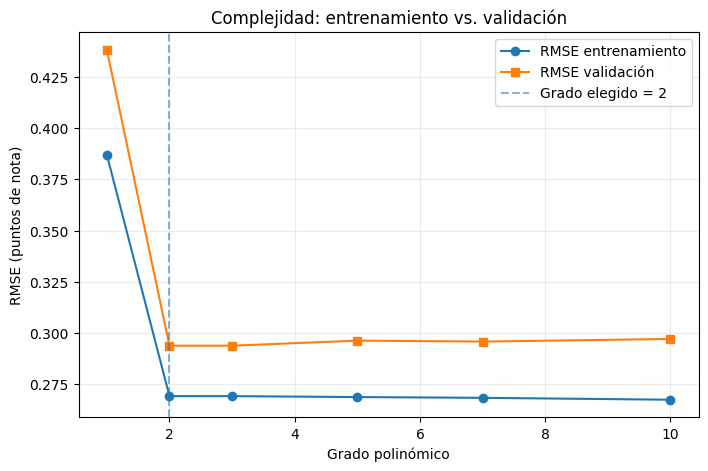

Mira si entrenamiento cae mientras validación deja de mejorar: posible sobreajuste.


In [ ]:
plt.figure(figsize=(8,5))
plt.plot(tabla_grados.Grado,tabla_grados['RMSE entreno'],'o-',label='RMSE entrenamiento')
plt.plot(tabla_grados.Grado,tabla_grados['RMSE validación'],'s-',label='RMSE validación')
plt.axvline(gr_sel,ls='--',alpha=.55,label=f'Grado elegido = {gr_sel}')
plt.xlabel('Grado polinómico');plt.ylabel('RMSE (puntos de nota)')
plt.title('Complejidad: entrenamiento vs. validación')
plt.legend();plt.grid(alpha=.25);plt.show()
print('Mira si entrenamiento cae mientras validación deja de mejorar: posible sobreajuste.')

## 17. Comprobar las curvas de varios grados en una misma gráfica

Observaremos cómo cambia la forma de la predicción. Para grados elevados, especialmente cerca de los extremos, pueden aparecer oscilaciones que no representan una tendencia confiable.

**Eje X:** horas de estudio. **Eje Y:** nota predicha. **Puntos:** datos de entrenamiento.

Un polinomio de grado alto puede generar notas fuera del rango [0,5]; si ocurre, no es un error de Python sino una limitación del modelo lineal no restringido. **No extrapoles** fuera de 0 a 20 horas basándote en esta simulación.

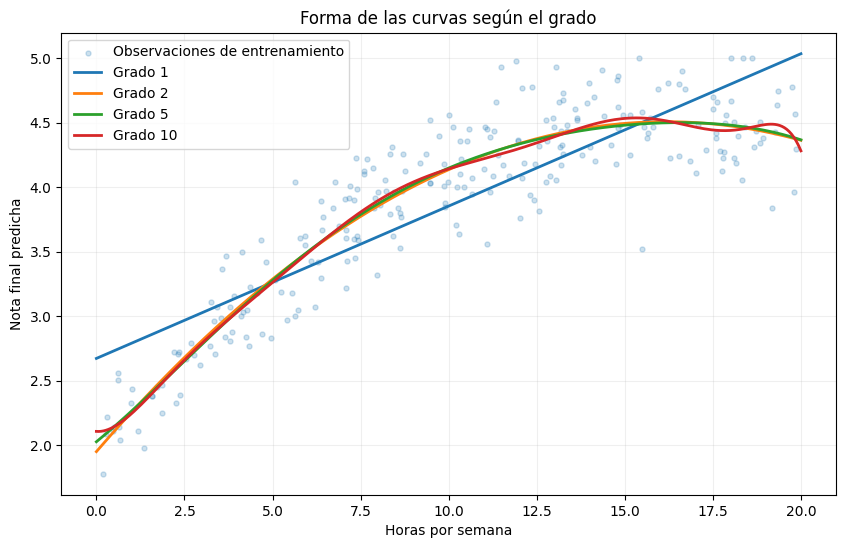

In [ ]:
plt.figure(figsize=(10,6))
plt.scatter(X_entrena.horas_estudio_semana,y_entrena,s=13,alpha=.22,label='Observaciones de entrenamiento')
for g in [1,2,5,10]:
    plt.plot(malla.horas_estudio_semana,modelos_grados[g].predict(malla),lw=2,label=f'Grado {g}')
plt.xlabel('Horas por semana');plt.ylabel('Nota final predicha')
plt.title('Forma de las curvas según el grado');plt.grid(alpha=.2);plt.legend();plt.show()

## 18. Usar la prueba **una sola vez** después de escoger grado

Hasta aquí solo hemos usado entrenamiento y validación para decidir el grado. Ahora:

1. Elegimos el grado que obtuvo **menor RMSE de validación**.
2. Creamos **un modelo nuevo** con ese grado.
3. Volvemos a entrenarlo con la unión de entrenamiento y validación, es decir, 80 % de los datos.
4. Evaluamos una sola vez sobre el 20 % reservado para prueba.

¿Por qué reentrenar? Porque una vez fijada la complejidad, los datos de validación pueden ayudar a estimar los coeficientes con más información. El conjunto de prueba se mantiene independiente para la evaluación final.

**Cuidado:** si observamos las métricas de prueba y luego cambiamos el grado muchas veces para mejorarlas, estaríamos usando prueba para seleccionar el modelo. En ese caso dejaría de ser un examen independiente.

In [ ]:
modelo_final=crear_modelo_polinomico(gr_sel)
modelo_final.fit(X_pre,y_pre)
pred_final=modelo_final.predict(X_prueba)
resultado_final=metricas(y_prueba,pred_final)
dummy_final=DummyRegressor(strategy='mean').fit(X_pre,y_pre)
resultado_dummy=metricas(y_prueba,dummy_final.predict(X_prueba))
print('Grado final fijado antes de evaluar prueba:',gr_sel)
print('Tamaño entrenamiento+validación:',len(X_pre),'| tamaño prueba:',len(X_prueba))
display(pd.DataFrame([
    {'Modelo':'Dummy (media de entrenamiento+validación)',**resultado_dummy},
    {'Modelo':f'Polinomio grado {gr_sel}',**resultado_final}
]).round(4))
print(f"Interpretación: MAE final={resultado_final['MAE']:.3f} puntos de nota; ",
      f"RMSE={resultado_final['RMSE']:.3f} puntos; R²={resultado_final['R2']:.3f}.")
print(f"Reducción porcentual del MAE frente a Dummy (prueba) = {100*(1-resultado_final['MAE']/resultado_dummy['MAE']):.2f}%")

Grado final fijado antes de evaluar prueba: 2
Tamaño entrenamiento+validación: 336 | tamaño prueba: 84


,Modelo,MAE,MSE,RMSE,R2
0,Dummy (media de entrenamiento+validación),0.6317,0.5814,0.7625,-0.0112
1,Polinomio grado 2,0.2244,0.0764,0.2764,0.8671


Interpretación: MAE final=0.224 puntos de nota;  RMSE=0.276 puntos; R²=0.867.
Reducción porcentual del MAE frente a Dummy (prueba) = 64.48%


### ¿Cuándo podemos decir que el modelo es «bueno»?

En este conjunto ficticio, es favorable que el modelo seleccionado presente errores relativamente bajos en la escala de 0 a 5, un R² positivo y una mejora medible frente a `DummyRegressor` en prueba. **No existe un umbral universal de R²** que lo haga bueno o malo para todos los contextos.

Los resultados son observacionales dentro de una simulación: no implican que más horas produzcan por sí solas una mejora causal, ni que podamos predecir igual en universidades reales.

Un valor cercano a 0 de MAE significa un error absoluto promedio pequeño. Un RMSE mayor que MAE es normal, debido al peso de errores grandes. Un R² negativo es posible incluso con un modelo entrenado sin errores de programación.

## 19. Tabla de estudiantes reales y predichos: interpretar signo y magnitud de residuos

Construiremos una tabla con las primeras diez observaciones **de prueba**. `error_real_menos_predicho` es positivo si subestimamos la nota y negativo si la sobreestimamos. `error_absoluto` representa el tamaño del error ignorando el signo.

Esta tabla permite mirar casos individuales, pero una decena de filas **no** es suficiente para medir el rendimiento global: las métricas anteriores utilizan las 84 observaciones de prueba.

In [ ]:
tabla_pred=pd.DataFrame({
    'horas':X_prueba['horas_estudio_semana'].to_numpy(),
    'nota_real':y_prueba.to_numpy(),
    'nota_predicha':pred_final
})
tabla_pred['residual_real_menos_predicho']=tabla_pred.nota_real-tabla_pred.nota_predicha
tabla_pred['error_absoluto']=tabla_pred.residual_real_menos_predicho.abs()
display(tabla_pred.head(10).round(4))
print('Caso 1: nota real=',round(tabla_pred.iloc[0].nota_real,3),
      'predicha=',round(tabla_pred.iloc[0].nota_predicha,3),
      'residual=',round(tabla_pred.iloc[0].residual_real_menos_predicho,3))
print('Interpretación caso 1:', 'Subestimación' if tabla_pred.iloc[0].residual_real_menos_predicho>0 else 'Sobreestimación' if tabla_pred.iloc[0].residual_real_menos_predicho<0 else 'Predicción exacta')

,horas,nota_real,nota_predicha,residual_real_menos_predicho,error_absoluto
0,4.33,3.20,3.1443,0.0557,0.0557
1,14.23,4.64,4.4608,0.1792,0.1792
2,1.48,2.15,2.4099,-0.2599,0.2599
3,4.24,2.65,3.1235,-0.4735,0.4735
4,15.22,4.37,4.4871,-0.1171,0.1171
5,19.17,4.64,4.4009,0.2391,0.2391
6,14.90,4.60,4.4807,0.1193,0.1193
7,16.84,4.27,4.4887,-0.2187,0.2187
8,4.19,3.05,3.1119,-0.0619,0.0619
9,15.48,5.00,4.4908,0.5092,0.5092


Caso 1: nota real= 3.2 predicha= 3.144 residual= 0.056
Interpretación caso 1: Subestimación


## 20. Gráficas diagnósticas: predicho frente a real y residuos frente a predicho

**Gráfica izquierda:**

- Horizontal = notas reales de prueba; vertical = notas predichas.
- Diagonal = predicción perfecta \(\hat y=y\).
- Punto **por encima** de la diagonal: el modelo predice **más** de lo real (sobreestimación).
- Punto **por debajo**: predice **menos** de lo real (subestimación).
- Cuanto más cerca de la diagonal, menor es el error absoluto de esa observación.

**Gráfica derecha:**

- Horizontal = nota predicha; vertical = residual \(y-\hat y\).
- Línea horizontal cero = ausencia de error.
- Residual **positivo** = el modelo subestimó.
- Residual **negativo** = sobreestimó.
- Curvas, bandas o «embudos» pueden señalar especificación inadecuada, heterocedasticidad o comportamiento dependiente del nivel predicho.

**Precaución:** observar una nube relativamente dispersa alrededor de cero no prueba normalidad, independencia ni homocedasticidad. Para esas propiedades se requieren análisis específicos; en estos datos simulados no debemos hacer inferencias poblacionales.

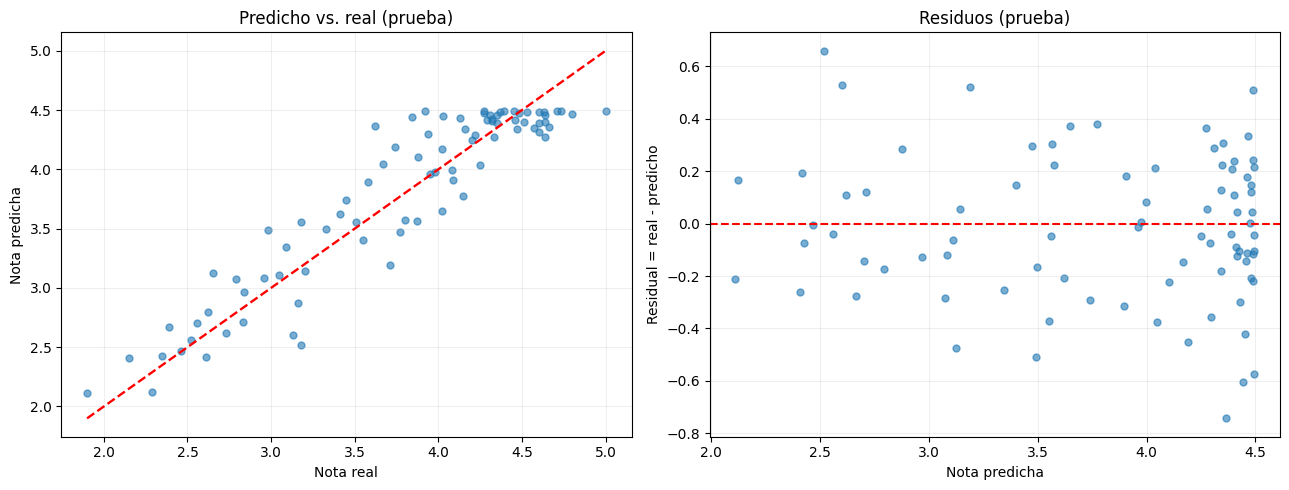

Media residual (prueba): -0.0192
Desviación estándar residual (prueba): 0.2774
Residuo mínimo y máximo: -0.7433 0.6602


In [ ]:
residuos = y_prueba.to_numpy()-pred_final
fig,axs=plt.subplots(1,2,figsize=(13,5))
axs[0].scatter(y_prueba,pred_final,alpha=.6,s=25)
minimo=min(float(y_prueba.min()),float(np.min(pred_final)))
maximo=max(float(y_prueba.max()),float(np.max(pred_final)))
axs[0].plot([minimo,maximo],[minimo,maximo],'r--',lw=1.7)
axs[0].set(xlabel='Nota real',ylabel='Nota predicha',title='Predicho vs. real (prueba)')
axs[0].grid(alpha=.2)
axs[1].scatter(pred_final,residuos,alpha=.6,s=25)
axs[1].axhline(0,color='r',linestyle='--')
axs[1].set(xlabel='Nota predicha',ylabel='Residual = real - predicho',title='Residuos (prueba)')
axs[1].grid(alpha=.2)
plt.tight_layout();plt.show()
print('Media residual (prueba):',round(float(np.mean(residuos)),4))
print('Desviación estándar residual (prueba):',round(float(np.std(residuos,ddof=1)),4))
print('Residuo mínimo y máximo:',round(float(np.min(residuos)),4),round(float(np.max(residuos)),4))

## 21. Histograma de residuos y casos con mayor error

Un histograma muestra cuántos residuos caen en distintos intervalos. Una forma relativamente simétrica alrededor de cero puede ser compatible con errores equilibrados, pero **no demuestra** que sean normales.

También revisaremos los cinco mayores errores absolutos de prueba. Inspeccionar casos extremos ayuda a reconocer limitaciones y cuestionar predicciones individuales. El máximo observado no debe confundirse con el error máximo posible en futuros datos.

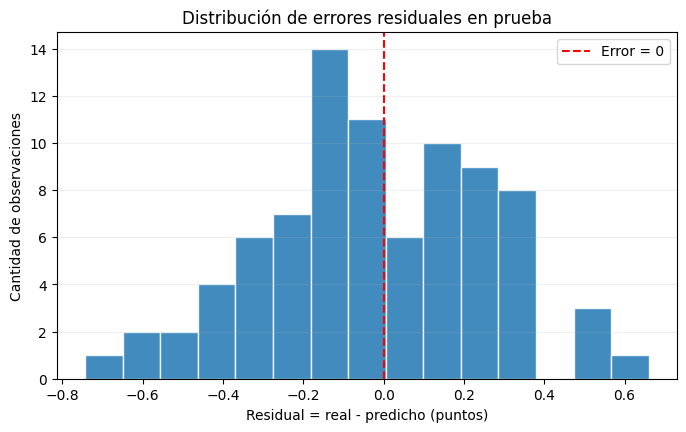

Los 5 casos de mayor error absoluto en prueba:


,horas,nota_real,nota_predicha,residual_real_menos_predicho,error_absoluto
40,12.42,3.62,4.3633,-0.7433,0.7433
48,1.87,3.18,2.5198,0.6602,0.6602
13,18.37,3.84,4.4430,-0.6030,0.6030
77,15.75,3.92,4.4932,-0.5732,0.5732
57,2.17,3.13,2.6023,0.5277,0.5277


In [ ]:
plt.figure(figsize=(8,4.5))
plt.hist(residuos,bins=15,edgecolor='white',alpha=.85)
plt.axvline(0,color='r',ls='--',label='Error = 0')
plt.xlabel('Residual = real - predicho (puntos)');plt.ylabel('Cantidad de observaciones')
plt.title('Distribución de errores residuales en prueba')
plt.legend();plt.grid(axis='y',alpha=.2);plt.show()
print('Los 5 casos de mayor error absoluto en prueba:')
display(tabla_pred.nlargest(5,'error_absoluto').round(4))

## 22. Validación cruzada de cinco particiones para estimar estabilidad

La elección anterior se basó en **una sola partición de validación**. Para reforzarla, aplicaremos `KFold(n_splits=5, shuffle=True, random_state=42)` sobre los 336 registros que conforman entrenamiento+validación (el conjunto de prueba permanece excluido).

En cada iteración, 4 partes sirven para entrenamiento y 1 para validación. Obtenemos cinco MAE y cinco R². La media resume el rendimiento aproximado y la desviación estándar describe la variación **entre particiones**, no el error de cada estudiante.

`cross_val_score` devuelve negativos de MAE cuando usamos `neg_mean_absolute_error`, porque sigue una convención de puntuaciones en la que «mayor es mejor». Multiplicaremos por −1 para expresar el MAE positivo habitual.

**Aviso metodológico:** si empleamos estas mismas particiones para seleccionar el grado y luego comunicamos su rendimiento como evaluación final independiente, habría optimismo de selección. Aquí la selección ya se hizo mediante validación y la prueba se reservó para el paso anterior.

In [ ]:
cv=KFold(n_splits=5,shuffle=True,random_state=42)
mae_cv=-cross_val_score(crear_modelo_polinomico(gr_sel),X_pre,y_pre,
                        scoring='neg_mean_absolute_error',cv=cv)
r2_cv=cross_val_score(crear_modelo_polinomico(gr_sel),X_pre,y_pre,
                      scoring='r2',cv=cv)
cv_tabla=pd.DataFrame({'Partición':[1,2,3,4,5],'MAE':mae_cv,'R2':r2_cv})
display(cv_tabla.round(4))
print(f"Media MAE = {mae_cv.mean():.4f} | Desviación entre particiones = {mae_cv.std(ddof=1):.4f}")
print(f"Media R² = {r2_cv.mean():.4f} | Desviación entre particiones = {r2_cv.std(ddof=1):.4f}")

,Partición,MAE,R2
0,1,0.2457,0.8635
1,2,0.1980,0.8823
2,3,0.2336,0.8033
3,4,0.2064,0.8864
4,5,0.2317,0.8752


Media MAE = 0.2231 | Desviación entre particiones = 0.0200
Media R² = 0.8621 | Desviación entre particiones = 0.0340


## 23. ¿Qué ocurre fuera del intervalo observado? Extrapolación y notas imposibles

La muestra fue generada con horas entre 0 y 20. Si introducimos 30 o 40 horas, estamos **extrapolando** más allá del dominio observado. Los polinomios, sobre todo los de grado elevado, pueden crecer o decrecer bruscamente fuera del intervalo de ajuste.

Compararemos la estimación del modelo final para 0, 5, 10, 15, 20, 30 y 40 horas. Las dos últimas **no** deben utilizarse como recomendaciones académicas ni como predicciones fiables: son una demostración de límites de extrapolación.

El algoritmo tampoco impone que las notas estén en [0,5]. Que una predicción supere 5 o sea negativa no significa que Python esté roto; evidencia que la función lineal sobre las variables transformadas no tiene esa restricción.

In [ ]:
horas_nuevas=pd.DataFrame({'horas_estudio_semana':[0.,5.,10.,15.,20.,30.,40.]})
pronosticos=modelo_final.predict(horas_nuevas)
tabla_extrap=pd.DataFrame({'horas':horas_nuevas.horas_estudio_semana,
                            'prediccion':pronosticos,
                            'en_rango_de_entrenamiento':[True]*5+[False]*2})
display(tabla_extrap.round(4))
print('Los casos de 30 y 40 horas son extrapolaciones: NO validar ni recomendar usando estos valores.')

,horas,prediccion,en_rango_de_entrenamiento
0,0.0,1.9659,True
1,5.0,3.2938,True
2,10.0,4.1328,True
3,15.0,4.4829,True
4,20.0,4.3441,True
5,30.0,2.5996,False
6,40.0,-1.1005,False


Los casos de 30 y 40 horas son extrapolaciones: NO validar ni recomendar usando estos valores.


## 24. MÓDULO AVANZADO: regresión polinómica **con varias variables**

En el módulo anterior, la predicción utilizó **solo horas de estudio**. Ahora retomamos la idea de regresión múltiple del notebook previo: podemos incluir también promedio anterior, asistencia y trabajo.

Para que la interpretación sea manejable, crearemos manualmente las cinco columnas:

\[
\hat y=b_0+b_1h+b_2h^2+b_3p+b_4a+b_5t.
\]

De ese modo, la curvatura depende de horas; las otras variables aparecen **linealmente**. Esto NO es idéntico a aplicar `PolynomialFeatures(degree=2)` indiscriminadamente sobre cuatro variables, ya que dicha función genera además cuadrados de todas las variables e interacciones entre ellas.

**Comparación justa:** entrenaremos con los mismos 336 registros anteriores y evaluaremos en los mismos 84 registros de prueba. Este bloque es una **demostración adicional** y no debe utilizarse para reemplazar el modelo final previamente seleccionado después de mirar sus resultados de prueba.

**Aviso:** la nota simulada se generó usando precisamente estas variables, de modo que esperamos que el modelo múltiple capture variación que el modelo univariado no puede representar. Esto es una propiedad del diseño experimental sintético, no evidencia sobre poblaciones reales.

In [ ]:
columnas_multiples=['horas_estudio_semana','promedio_anterior','asistencia_pct','trabaja']
Xmulti=datos[columnas_multiples].copy()
Xmulti['horas_al_cuadrado']=Xmulti['horas_estudio_semana']**2
Xmulti_pre=Xmulti.loc[X_pre.index]
Xmulti_prueba=Xmulti.loc[X_prueba.index]
modelo_multiple=LinearRegression()
modelo_multiple.fit(Xmulti_pre,y_pre)
pred_multi=modelo_multiple.predict(Xmulti_prueba)
coef_multi=pd.DataFrame({'Variable':Xmulti.columns,'Coeficiente estimado':modelo_multiple.coef_})
print('Intercepto múltiple:',round(float(modelo_multiple.intercept_),6))
display(coef_multi.round(6))
print('Nota: el intercepto y los coeficientes se estimaron de 336 casos, con todas las variables.')

Intercepto múltiple: 0.122308


,Variable,Coeficiente estimado
0,horas_estudio_semana,0.309362
1,promedio_anterior,0.363788
2,asistencia_pct,0.007495
3,trabaja,-0.100491
4,horas_al_cuadrado,-0.009416


Nota: el intercepto y los coeficientes se estimaron de 336 casos, con todas las variables.


### Interpretación variable por variable del modelo múltiple

- **`horas_estudio_semana`:** su coeficiente representa el término lineal, pero **no** el cambio fijo por una hora, ya que también interviene `horas_al_cuadrado`.
- **`horas_al_cuadrado`:** establece cómo cambia la pendiente al aumentar las horas. Su unidad es puntos de nota/hora².
- **`promedio_anterior`:** cambio predicho por un punto adicional de promedio previo, **manteniendo las otras variables constantes**.
- **`asistencia_pct`:** cambio predicho por **un punto porcentual** adicional (por ejemplo de 80 % a 81 %), manteniendo constantes las demás variables.
- **`trabaja`:** diferencia estimada entre categorías 1 y 0, manteniendo constantes los demás predictores. **No demuestra que trabajar cause un descenso de notas**.
- **Intercepto:** resultado extrapolado cuando todas las variables son cero; esas condiciones están fuera del dominio habitual, por lo que no se interpreta literalmente como un estudiante real.

**¿Por qué los coeficientes difieren de los valores de simulación?** Muestra finita, ruido, redondeo y variación entre predictores. La regresión estima, no conoce el mecanismo original.

A diferencia del modelo con una sola variable, aquí la curvatura asociada con las horas se interpreta **controlando estadísticamente** las otras características incluidas.

In [ ]:
comparar_final=pd.DataFrame([
    {'Modelo':f'Polinomio simple grado {gr_sel}',**resultado_final},
    {'Modelo':'Múltiple con h² y otras 3 variables',**metricas(y_prueba,pred_multi)}
])
display(comparar_final.round(4))
print('Esta comparación es descriptiva; el diseño simulado favorece al modelo que usa las variables generadoras.')
print('No elegir repetidamente nuevos modelos mirando el test: eso contamina la evaluación.')

,Modelo,MAE,MSE,RMSE,R2
0,Polinomio simple grado 2,0.2244,0.0764,0.2764,0.8671
1,Múltiple con h² y otras 3 variables,0.1690,0.0425,0.2062,0.9261


Esta comparación es descriptiva; el diseño simulado favorece al modelo que usa las variables generadoras.
No elegir repetidamente nuevos modelos mirando el test: eso contamina la evaluación.


## 25. ¿Qué hace `PolynomialFeatures` con más de una variable? Interacciones

Para dos columnas \(h\) y \(p\), grado 2 y `include_bias=False`, se generan:

\[
h,\quad p,\quad h^2,\quad hp,\quad p^2.
\]

El término \(hp\) es una **interacción**: permite que la contribución de horas dependa del promedio anterior. Los cuadrados \(h^2\) y \(p^2\) permiten curvaturas para ambos.

Con cuatro variables y grado 2 aparecen muchas más características transformadas, aunque solo haya cuatro columnas originales. Una cantidad mayor de variables puede aumentar complejidad, riesgo de sobreajuste y dificultad interpretativa.

Aquí observaremos solo la generación de características, sin convertirla en el modelo final. Esto distingue **transformar** de **entrenar** y evita presentar un modelo no validado como superior.

In [ ]:
dos_variables=datos[['horas_estudio_semana','promedio_anterior']].head(3)
transformador_2var=PolynomialFeatures(degree=2,include_bias=False)
matriz_2var=transformador_2var.fit_transform(dos_variables)
display(pd.DataFrame(matriz_2var,columns=transformador_2var.get_feature_names_out(dos_variables.columns)))
print('Columnas originales:',dos_variables.shape[1],
      '| columnas transformadas:',matriz_2var.shape[1])
cuatro_var=PolynomialFeatures(degree=2,include_bias=False)
cuatro_var.fit(Xmulti_pre[columnas_multiples])
print('Con 4 variables originales y grado 2, cantidad de columnas:',
      len(cuatro_var.get_feature_names_out()))
print('Lista:',list(cuatro_var.get_feature_names_out()))

,horas_estudio_semana,promedio_anterior,horas_estudio_semana^2,horas_estudio_semana promedio_anterior,promedio_anterior^2
0,3.58,3.56,12.8164,12.7448,12.6736
1,12.80,3.83,163.8400,49.0240,14.6689
2,9.35,4.36,87.4225,40.7660,19.0096


Columnas originales: 2 | columnas transformadas: 5
Con 4 variables originales y grado 2, cantidad de columnas: 14
Lista: ['horas_estudio_semana', 'promedio_anterior', 'asistencia_pct', 'trabaja', 'horas_estudio_semana^2', 'horas_estudio_semana promedio_anterior', 'horas_estudio_semana asistencia_pct', 'horas_estudio_semana trabaja', 'promedio_anterior^2', 'promedio_anterior asistencia_pct', 'promedio_anterior trabaja', 'asistencia_pct^2', 'asistencia_pct trabaja', 'trabaja^2']


## 26. Conclusión automática construida con los resultados **reales de esta ejecución**

Este cierre no contiene métricas inventadas ni un juicio fijo de «perfecto»: se genera usando las cifras del propio notebook.

**Criterios de lectura:**

- Si R² de prueba es positivo, mejora la referencia basada en la media **del conjunto de prueba** respecto a suma de errores cuadrados.
- Si R² fuera negativo, sería peor que esa referencia específica.
- Si el MAE disminuye frente a `DummyRegressor`, el modelo aporta predicciones más próximas en promedio.
- La calidad depende de contexto, incertidumbre, valores extremos, estabilidad, generalización y uso; no solo de R².

Los coeficientes de un modelo predictivo con variables correlacionadas no prueban causalidad y la extrapolación puede ser especialmente peligrosa con polinomios.

In [ ]:
print('CONCLUSIÓN DE LA EJECUCIÓN')
print(f'Se analizaron {len(datos)} observaciones sintéticas y se reservó prueba de {len(y_prueba)} casos.')
print(f'El grado elegido por validación fue {gr_sel}.')
print(f'En prueba: MAE={resultado_final["MAE"]:.4f} puntos, '
      f'MSE={resultado_final["MSE"]:.4f} puntos², '
      f'RMSE={resultado_final["RMSE"]:.4f} puntos, R²={resultado_final["R2"]:.4f}.')
print(f'Dummy en prueba: MAE={resultado_dummy["MAE"]:.4f}, R²={resultado_dummy["R2"]:.4f}.')
if resultado_final['MAE']<resultado_dummy['MAE']:
    print('El polinomio redujo el error absoluto medio respecto al baseline en prueba.')
else:
    print('El polinomio NO redujo el MAE respecto al baseline en prueba.')
print('R² positivo:' if resultado_final['R2']>0 else 'R² no positivo:',
      'interpretar como comparación matemática, NO porcentaje de aciertos.')
print('Limitaciones: datos artificiales, una única muestra de prueba, extrapolación y ausencia de causalidad.')

CONCLUSIÓN DE LA EJECUCIÓN
Se analizaron 420 observaciones sintéticas y se reservó prueba de 84 casos.
El grado elegido por validación fue 2.
En prueba: MAE=0.2244 puntos, MSE=0.0764 puntos², RMSE=0.2764 puntos, R²=0.8671.
Dummy en prueba: MAE=0.6317, R²=-0.0112.
El polinomio redujo el error absoluto medio respecto al baseline en prueba.
R² positivo: interpretar como comparación matemática, NO porcentaje de aciertos.
Limitaciones: datos artificiales, una única muestra de prueba, extrapolación y ausencia de causalidad.


## 27. Preguntas para discutir después de ejecutar el notebook

Contesta con números **obtenidos de la ejecución** y explicaciones propias:

1. ¿Cuántos estudiantes y columnas tiene la base? ¿Cuáles son X e y en la primera parte?
2. ¿De dónde viene la variable `horas²`? Calcula su valor para 3, 7 y 12 horas.
3. Escribe las ecuaciones completas de grado 1 y grado 2 **con coeficientes estimados**.
4. ¿Qué implica un coeficiente cuadrático negativo? ¿Por qué el coeficiente lineal no es una pendiente constante?
5. Calcula manualmente la predicción del grado 2 para 10 horas. Identifica intercepto, aporte lineal y cuadrático.
6. ¿Qué indica cada cifra de `describe()` para la nota final: `count`, `mean`, `std`, `min`, cuartiles, `max`?
7. ¿Qué significan el MAE, MSE, RMSE y R² de grado 1 y grado 2 en validación? Incluye unidades.
8. ¿Por qué es incorrecto decir que R²=0,80 significa «80 % de estudiantes acertados»?
9. ¿Qué modelo mejora el MAE de `DummyRegressor`? ¿En qué porcentaje?
10. ¿Qué grado se seleccionó y con qué criterio? ¿Por qué no utilizar el conjunto de prueba para seleccionarlo?
11. ¿Qué muestran los gráficos de predicción frente a real y de residuos? Explica el signo de los errores.
12. ¿Hay señales visuales de sobreajuste? Contrasta RMSE en entrenamiento con validación.
13. ¿Qué significa la variabilidad entre particiones de validación cruzada?
14. ¿Por qué no debemos confiar en predicciones con 30 o 40 horas semanales?
15. En el modelo múltiple, ¿cómo interpretar `trabaja`, `asistencia_pct` y `horas²` sin hacer afirmaciones causales?
16. Concluye si el modelo es **adecuado para esta simulación**, aportando al menos tres resultados cuantitativos y dos limitaciones.

**Actividad de comprobación:** ejecuta otra vez todo el notebook sin modificar `SEMILLA`. Los resultados deberían ser reproducibles salvo diferencias menores por versiones numéricas de bibliotecas.

## 28. Glosario rápido para consultas durante clase

| Concepto | Explicación directa |
|---|---|
| Predictor (X) | Información utilizada para calcular la respuesta |
| Respuesta (y) | Resultado observado que se quiere predecir |
| Grado | Mayor potencia de la función polinómica |
| Intercepto | Predicción matemática cuando las características valen 0 |
| Coeficiente | Peso estimado de un término de la ecuación |
| `fit()` | Estima parámetros a partir de datos de entrenamiento |
| `transform()` | Convierte variables originales en nuevas columnas |
| `predict()` | Calcula valores estimados mediante parámetros aprendidos |
| Residual | Real menos predicho, con signo |
| MAE | Promedio del valor absoluto de los errores |
| MSE | Promedio de errores al cuadrado |
| RMSE | Raíz del MSE, en las unidades de y |
| R² | Comparación de errores cuadrados frente a predictor medio |
| Subajuste | Modelo insuficientemente flexible para la estructura existente |
| Sobreajuste | Modelo que aprende detalles del entrenamiento que no generalizan |
| Validación | Datos para comparar alternativas antes del examen final |
| Prueba | Datos reservados para estimación final, no para ajustar el modelo |
| Extrapolación | Predicción fuera de los valores observados de X |
| Interacción | Término que permite que el efecto de una variable dependa de otra |

## Referencias bibliográficas (APA 7)

James, G., Witten, D., Hastie, T., Tibshirani, R., & Taylor, J. (2023). *An introduction to statistical learning: With applications in Python*. Springer. https://doi.org/10.1007/978-3-031-38747-0

Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., Blondel, M., Prettenhofer, P., Weiss, R., Dubourg, V., Vanderplas, J., Passos, A., Cournapeau, D., Brucher, M., Perrot, M., & Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830. https://www.jmlr.org/papers/v12/pedregosa11a.html

Scikit-learn developers. (s. f.). *PolynomialFeatures*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.preprocessing.PolynomialFeatures.html

Scikit-learn developers. (s. f.). *Pipeline*. Scikit-learn. https://scikit-learn.org/stable/modules/generated/sklearn.pipeline.Pipeline.html

Scikit-learn developers. (s. f.). *Regression metrics*. Scikit-learn. https://scikit-learn.org/stable/modules/model_evaluation.html#regression-metrics

**Nota sobre referencias:** las fuentes metodológicas respaldan los conceptos de regresión y evaluación; los valores numéricos de este notebook provienen exclusivamente de la simulación ejecutada.